### SIF retrieval bias vs aerosol optical depth — GCHPIO aerosols, 0.05 cm⁻¹ grid (n = 200)

Same analysis as `compare_retrieval_bias_against_aod.ipynb`, for the ensemble generated by
`generate_test_spec_lambertian_gchpio.jl` (TOMAS bin-resolved aerosol optics, 0.05 cm⁻¹ spectral grid, δBGE truncation).

* AOD comes from the ensemble itself (`aod`, GCHPIO column AOD at each OCI band centre), so it is exactly the aerosol that went into the RT.
  The GCHP column file (`gchp_ocean_columns_n500.nc`) is only used for the sea-salt fraction at 550 nm (species path, a composition indicator).
* Two retrievals of the same spectra: **w756** (640–756 nm) and **O2A** (640–780 nm).
* ΔSIF = retrieved − true water-leaving SIF at 678 nm. At 0.05 cm⁻¹ many O2A fits stop at the 15-iteration cap (`status = 0`)
  and the converged subset is not representative, so results are shown for converged samples and for all samples (`STATUS_FILTER`).

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

base = "/home/zhe2/FraLab/PACE_redSIF_PACE/surrogate_meas/full_RT_construction"
run_dir = f"{base}/output_new_Lambertian_gchpio_finerwavnum0p05"

# RT-generated samples (GCHPIO aerosols); `aod` is (sample, band)
rt_samples = xr.open_dataset(f"{run_dir}/rt_toa_ensemble_lambertian_gchpio.nc")

# retrievals to be evaluated (same spectra, two fitting windows)
retrieval_names = {
    "w756 (640–756 nm)": f"{run_dir}/rt_retrieval_lambertian_200_nPC15_npoly3.nc",
    "O2A (640–780 nm)":  f"{run_dir}/rt_retrieval_lambertian_200_O2A_nPC15_npoly3.nc",
}
retrievals = {k: xr.open_dataset(v) for k, v in retrieval_names.items()}

# GCHP column file: only for the sea-salt fraction (species path, 550 nm)
columns = xr.open_dataset(f"{base}/output_aerosol_profiles/gchp_ocean_columns_n500.nc")

STATUS_FILTER = "converged"     # "converged" (status == 1) or "all"
UNITS = r"W m$^{-2}$ sr$^{-1}$ µm$^{-1}$"
print({k: v for k, v in rt_samples.attrs.items() if k in
       ("n_completed", "n_samples", "seed", "aerosol_optics", "aerosol_truncation", "ocean_yaml")})

{'n_completed': 200, 'n_samples': 200, 'seed': 20260913, 'ocean_yaml': '/home/zhe2/FraLab/PACE_redSIF_PACE/surrogate_meas/full_RT_construction/../configs/ocean_lambertian_1010_wavnum0p05.yaml', 'aerosol_optics': 'Google-RT GCHPIO TOMAS bin-resolved Mie, layer-resolved', 'aerosol_truncation': 'δBGE{Float64}'}


In [2]:
# per-sample AOD from the ensemble (GCHPIO), interpolated to fixed wavelengths
wl = rt_samples.wavelength.values
aod_band = rt_samples.aod.transpose("sample", "band").values            # (sample, band)
aod_at = lambda lam: np.array([np.interp(lam, wl, a) for a in aod_band])
aod_678 = aod_at(678.0)
aod_640, aod_780 = aod_at(640.0), aod_at(780.0)
angstrom = -np.log(aod_640 / aod_780) / np.log(640.0 / 780.0)         # Ångström exponent 640→780 nm

column_index = rt_samples.column_index.values                          # 1-based
assert column_index.min() >= 1, "aerosols were disabled in this ensemble (column_index = 0)"
icol = column_index - 1
ss_fraction = columns.ss_fraction.values[icol]                         # species path, 550 nm
aod_file_550 = columns.tau_ref.values[icol]

# retrieval results, checked against the ensemble truth
sif_678_true = rt_samples.sif_678.values
res = {}
for name, r in retrievals.items():
    assert np.allclose(r.sif_678_true.values, sif_678_true), name
    st = r.status.values
    res[name] = dict(delta=r.sif_678_ret.values - sif_678_true, status=st,
                     sel=(st == 1) if STATUS_FILTER == "converged" else np.isfinite(r.sif_678_ret.values))
    print(f"{name:20s} samples {st.size}, converged {np.sum(st == 1)}, "
          f"status counts {dict(zip(*np.unique(st, return_counts=True)))}, using {res[name]['sel'].sum()} ({STATUS_FILTER})")

w756 (640–756 nm)    samples 200, converged 198, status counts {0: 1, 1: 198, 2: 1}, using 198 (converged)
O2A (640–780 nm)     samples 200, converged 63, status counts {0: 137, 1: 63}, using 63 (converged)


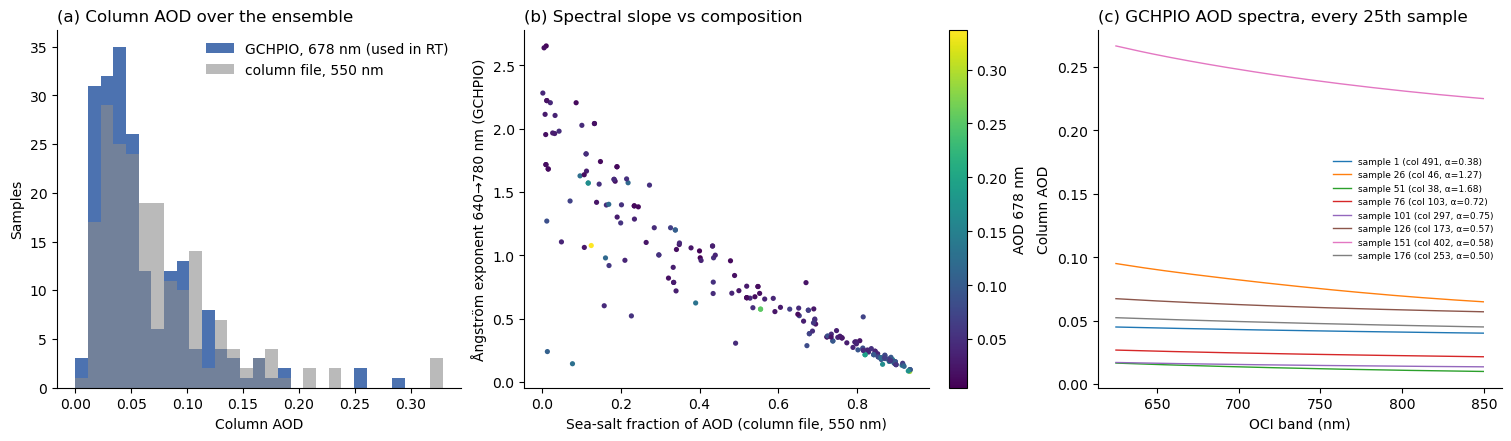

AOD(678): median 0.045, 5–95% [0.014, 0.156];  Ångström: median 0.59, 5–95% [0.14, 2.04]


In [3]:
# overview of the aerosol in the ensemble
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout="constrained")
bins = np.linspace(0, np.percentile(np.r_[aod_678, aod_file_550], 99.5), 30)
axes[0].hist(aod_678, bins=bins, color="#4C72B0", label="GCHPIO, 678 nm (used in RT)")
axes[0].hist(aod_file_550, bins=bins, color="0.55", alpha=0.6, label="column file, 550 nm")
axes[0].set_xlabel("Column AOD")
axes[0].set_ylabel("Samples")
axes[0].set_title("(a) Column AOD over the ensemble", loc="left")
axes[0].legend(frameon=False)

sc = axes[1].scatter(ss_fraction, angstrom, c=aod_678, s=14, cmap="viridis", linewidths=0)
axes[1].set_xlabel("Sea-salt fraction of AOD (column file, 550 nm)")
axes[1].set_ylabel("Ångström exponent 640→780 nm (GCHPIO)")
axes[1].set_title("(b) Spectral slope vs composition", loc="left")
fig.colorbar(sc, ax=axes[1], label="AOD 678 nm")

for i in range(0, aod_band.shape[0], 25):
    axes[2].plot(wl, aod_band[i], lw=1, label=f"sample {i + 1} (col {column_index[i]}, α={angstrom[i]:.2f})")
axes[2].set_xlabel("OCI band (nm)")
axes[2].set_ylabel("Column AOD")
axes[2].set_title("(c) GCHPIO AOD spectra, every 25th sample", loc="left")
axes[2].legend(fontsize=6.5, frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"AOD(678): median {np.median(aod_678):.3f}, 5–95% [{np.percentile(aod_678, 5):.3f}, {np.percentile(aod_678, 95):.3f}];  "
      f"Ångström: median {np.median(angstrom):.2f}, 5–95% [{np.percentile(angstrom, 5):.2f}, {np.percentile(angstrom, 95):.2f}]")

w756 (640–756 nm): ΔSIF (n=198) mean -0.0276, median -0.0274, SD 0.0181, RMSE 0.0330;  relative (true SIF > 0.05) median -11.6 %
O2A (640–780 nm): ΔSIF (n=63) mean -0.0337, median -0.0315, SD 0.0185, RMSE 0.0384;  relative (true SIF > 0.05) median -13.4 %


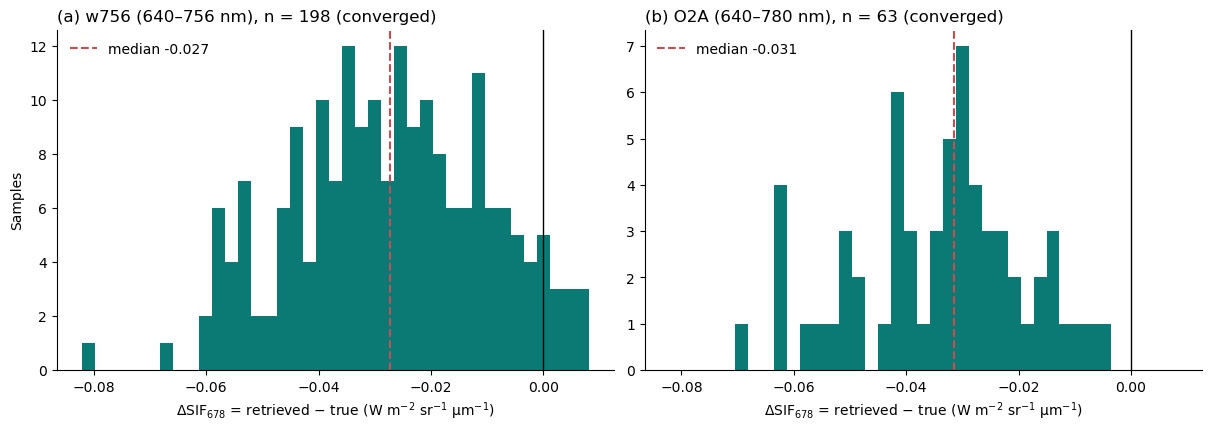

In [4]:
# histogram of ΔSIF per retrieval window (selected samples)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained", sharex=True)
lo, hi = np.percentile(np.concatenate([v["delta"][v["sel"]] for v in res.values()]), [0.5, 99.5])
for ax, (name, v), letter in zip(axes, res.items(), "ab"):
    d = v["delta"][v["sel"]]
    t = sif_678_true[v["sel"]]
    rel = d / np.where(np.abs(t) > 0.05, t, np.nan) * 100
    print(f"{name}: ΔSIF (n={d.size}) mean {d.mean():+.4f}, median {np.median(d):+.4f}, SD {d.std():.4f}, "
          f"RMSE {np.sqrt(np.mean(d**2)):.4f};  relative (true SIF > 0.05) median {np.nanmedian(rel):+.1f} %")
    ax.hist(d, bins=np.linspace(lo, hi, 40), color="#0B7A75")
    ax.axvline(0, color="k", lw=1)
    ax.axvline(np.median(d), color="#C44E52", lw=1.5, ls="--", label=f"median {np.median(d):+.3f}")
    ax.set_xlabel(f"ΔSIF$_{{678}}$ = retrieved − true ({UNITS})")
    ax.set_title(f"({letter}) {name}, n = {d.size} ({STATUS_FILTER})", loc="left")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Samples")
plt.show()

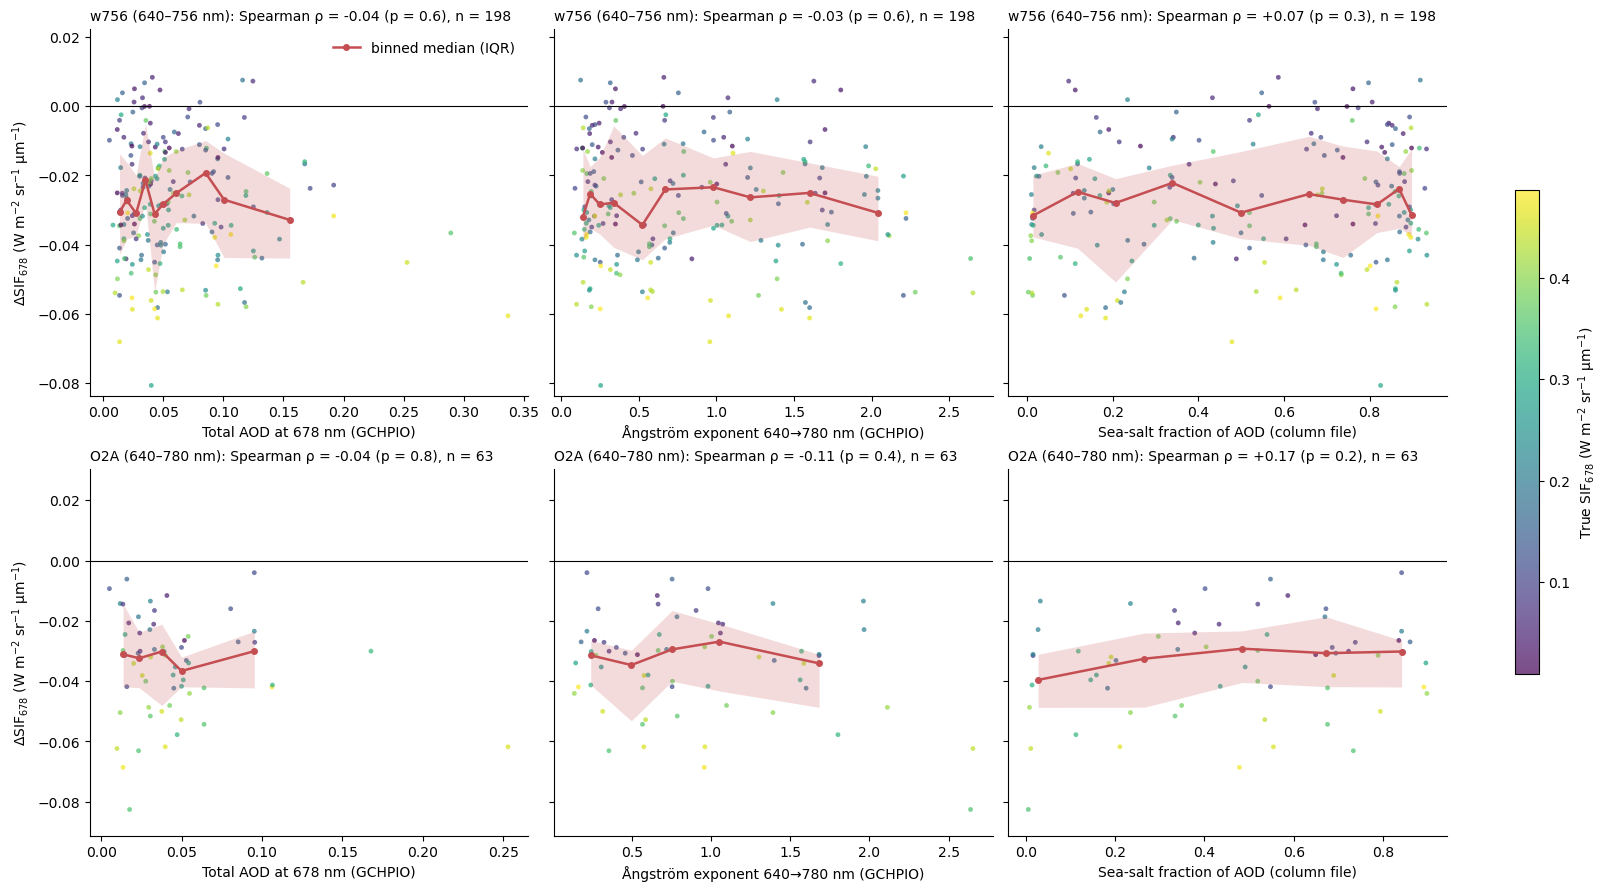

w756 (640–756 nm)    AOD678, backscatter side (vaz > 90°)   n=  99  Spearman ρ = -0.02 (p = 0.9)
w756 (640–756 nm)    AOD678, forward side (vaz ≤ 90°)       n=  99  Spearman ρ = -0.07 (p = 0.5)
w756 (640–756 nm)    AOD678, SZA < 40°                      n=  98  Spearman ρ = -0.08 (p = 0.4)
w756 (640–756 nm)    AOD678, SZA ≥ 40°                      n= 100  Spearman ρ = +0.00 (p = 1)
O2A (640–780 nm)     AOD678, backscatter side (vaz > 90°)   n=  37  Spearman ρ = +0.05 (p = 0.8)
O2A (640–780 nm)     AOD678, forward side (vaz ≤ 90°)       n=  26  Spearman ρ = -0.13 (p = 0.5)
O2A (640–780 nm)     AOD678, SZA < 40°                      n=  18  Spearman ρ = -0.12 (p = 0.6)
O2A (640–780 nm)     AOD678, SZA ≥ 40°                      n=  45  Spearman ρ = -0.03 (p = 0.8)


In [5]:
# ΔSIF against aerosol predictors, with binned medians (quantile bins → equal counts)
def binned_median(x, y, edges, min_n=8):
    k = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    mid, med, q1, q3 = [], [], [], []
    for i in range(len(edges) - 1):
        m = k == i
        if m.sum() >= min_n:
            mid.append(np.median(x[m]))
            q = np.percentile(y[m], [25, 50, 75])
            q1.append(q[0]); med.append(q[1]); q3.append(q[2])
    return map(np.asarray, (mid, med, q1, q3))

predictors = [
    ("Total AOD at 678 nm (GCHPIO)", aod_678),
    ("Ångström exponent 640→780 nm (GCHPIO)", angstrom),
    ("Sea-salt fraction of AOD (column file)", ss_fraction),
]
fig, axes = plt.subplots(len(res), 3, figsize=(16, 4.4 * len(res)), sharey="row", layout="constrained")
for row, (name, v) in enumerate(res.items()):
    sel = v["sel"]
    y = v["delta"][sel]
    nbin = 10 if sel.sum() >= 150 else 5
    for col, (pname, x_all) in enumerate(predictors):
        ax = axes[row, col]
        x = x_all[sel]
        sc = ax.scatter(x, y, s=12, c=sif_678_true[sel], cmap="viridis", alpha=0.7, linewidths=0)
        mid, med, q1, q3 = binned_median(x, y, np.quantile(x, np.linspace(0, 1, nbin + 1)))
        ax.fill_between(mid, q1, q3, color="#C44E52", alpha=0.2, linewidth=0)
        ax.plot(mid, med, "o-", color="#C44E52", lw=1.8, ms=4, label="binned median (IQR)")
        ax.axhline(0, color="k", lw=0.8)
        rho, p = stats.spearmanr(x, y)
        ax.set_title(f"{name}: Spearman ρ = {rho:+.2f} (p = {p:.1g}), n = {sel.sum()}", loc="left", fontsize=10)
        ax.set_xlabel(pname)
        ax.spines[["top", "right"]].set_visible(False)
    axes[row, 0].set_ylabel(f"ΔSIF$_{{678}}$ ({UNITS})")
    lo, hi = np.percentile(y, [1, 99])
    axes[row, 0].set_ylim(lo - 0.2 * (hi - lo), hi + 0.2 * (hi - lo))
axes[0, 0].legend(frameon=False, loc="upper right")
fig.colorbar(sc, ax=axes, label=f"True SIF$_{{678}}$ ({UNITS})", shrink=0.6)
plt.show()

# does the AOD dependence survive once geometry is accounted for?
vaz, sza = rt_samples.vaz.values, rt_samples.sza.values
for name, v in res.items():
    sel = v["sel"]
    for lab, m in (("backscatter side (vaz > 90°)", vaz > 90), ("forward side (vaz ≤ 90°)", vaz <= 90),
                   ("SZA < 40°", sza < 40), ("SZA ≥ 40°", sza >= 40)):
        mm = sel & m
        rho, p = stats.spearmanr(aod_678[mm], v["delta"][mm])
        print(f"{name:20s} AOD678, {lab:30s} n={mm.sum():4d}  Spearman ρ = {rho:+.2f} (p = {p:.1g})")

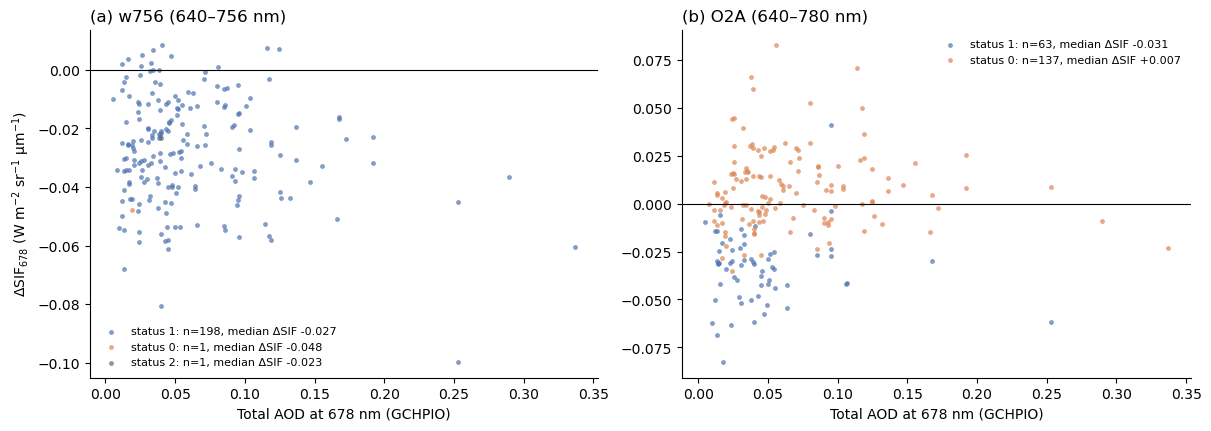

w756 (640–756 nm): AOD678 median converged 0.045 vs not 0.019 (Mann–Whitney p = 0.22)
O2A (640–780 nm): AOD678 median converged 0.038 vs not 0.050 (Mann–Whitney p = 0.00053)


In [6]:
# convergence check: is the converged subset representative? (status 1 = converged, 0 = hit the iteration cap)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
for ax, (name, v), letter in zip(axes, res.items(), "ab"):
    for s, col in ((1, "#4C72B0"), (0, "#DD8452"), (2, "0.4")):
        m = v["status"] == s
        if m.sum() == 0:
            continue
        ax.scatter(aod_678[m], v["delta"][m], s=12, color=col, alpha=0.7, linewidths=0,
                   label=f"status {s}: n={m.sum()}, median ΔSIF {np.median(v['delta'][m]):+.3f}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Total AOD at 678 nm (GCHPIO)")
    ax.set_title(f"({letter}) {name}", loc="left")
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"ΔSIF$_{{678}}$ ({UNITS})")
plt.show()
for name, v in res.items():
    a1, a0 = aod_678[v["status"] == 1], aod_678[v["status"] == 0]
    if a0.size and a1.size:
        print(f"{name}: AOD678 median converged {np.median(a1):.3f} vs not {np.median(a0):.3f} "
              f"(Mann–Whitney p = {stats.mannwhitneyu(a1, a0).pvalue:.2g})")